In [10]:
import pandas as pd
import numpy as np


df = pd.read_csv("https://raw.githubusercontent.com/laxmimerit/twitter-data/master/twitter4000.csv", encoding="latin1")
df.sample(5)  # returns random samples..

,twitts,sentiment
3488,can't wait to watch He's Just Not that into yo...,1
2840,Article on 529s. Just keep putting a little aw...,1
727,I'm searching for a new profile on my FS acc. ...,0
2086,4hrs of sleep and saved bt the bell marathon f...,1
1532,Twitter is driving me crazzzzzy tonight. There...,0


In [11]:
df.sentiment.value_counts()

sentiment
0    2000
1    2000
Name: count, dtype: int64

Balanced dataset

## Word Counts

In [12]:
df['word_count'] = df.twitts.apply(lambda x: len(str(x).split()))
df.word_count.max(), df.word_count.min() 

(32, 1)

## Characters Counts

In [13]:
def strip_spacing(string):
    s = string.split()  # list of words
    string = ''.join(s) # joining word without spacing
    return len(string)

In [14]:
df['char_count'] = df.twitts.apply(lambda x: strip_spacing(x))
df.sample(5)

,twitts,sentiment,word_count,char_count
1112,&quot;Bye Bye&quot; Cleveland...... ***Sassy***,0,4,44
905,i am not a sult!!!!!!! am i?,0,7,22
3306,Chasters let us start following each other &am...,1,17,82
2049,"@flexicar yes, joined last night (once I got h...",1,20,83
878,Spoke too quickly,0,3,15


## Average Word Length

In [15]:
df['avg_word_len'] = df.char_count / df.word_count
df.sample(5)

,twitts,sentiment,word_count,char_count,avg_word_len
3234,watching Grey's Anatomy-o how I love McDreamy ...,1,9,51,5.666667
3659,at the mall...going to the pool!!!!!!!,1,6,33,5.500000
253,NEEDS SOMETHING TO DO,0,4,18,4.500000
3857,"Twitter sucks, I'm only on here to follow Elle...",1,22,89,4.045455
3707,@thedailysurvey hello guys. can you play Love ...,1,19,91,4.789474


## Stop Words

#### **Stop Words is a built-in function which having a saved keywords like (is, this, the, on, in, before, after,....etc)**

In [16]:
import spacy
from spacy.lang.en.stop_words import STOP_WORDS as stopwords    

print(f"Number of Stopp Words: {len(stopwords)}\n"); print(f"Stop Words:\n{"="*100}\n{stopwords}")

Number of Stopp Words: 326

Stop Words:
{'become', 'former', 'sixty', 'unless', 'hereafter', 'even', 'beside', 'against', '‘d', 'now', 'himself', 'anywhere', 'throughout', 'at', 'of', 'whereby', 'next', 'full', 'may', 'how', 'or', 'others', 'everyone', 'if', 'give', 'whenever', 'must', 'us', 'perhaps', 'would', 'herein', 'the', 'latter', "'s", 'became', 'get', 'by', 'are', '’ve', 'thence', 'itself', 'up', 'therein', 'empty', '‘m', 'you', '’ll', 'been', 'everywhere', 'front', 'formerly', 'only', 'something', 'around', 'and', 'along', 'before', 'top', 'then', '’m', 'ever', 'less', 'whose', 'for', 'becomes', 'latterly', 'not', 'same', '’re', 'twelve', 'one', 'him', 'done', 'together', 'yet', 'between', 'another', 'whether', 'during', 'ten', 'every', 'had', '‘re', 'did', 'anyhow', "'ll", 'therefore', 'seems', 'always', 'because', 'take', 'last', 'nowhere', 'via', 'rather', 'other', 'thereby', 'might', 'amongst', 'eleven', 'so', 'their', 'never', 'all', 'four', 'n‘t', "'d", 'wherever', 'bei

In [17]:
df['stop_words_count'] = df.twitts.apply(lambda x: len([t for t in x.split() if t.lower() in stopwords]))
df.sample(5)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count
451,"@BLACKZOMBIE77 lol, nawww nothing man. im so b...",0,9,46,5.111111,2
3328,"@tommcfly hahahaha is very small, i don't know...",1,9,42,4.666667,4
1073,Feenin for a little debbie nutty bar.... We al...,0,14,61,4.357143,7
3617,@aphrodaisy as long as he's your former manage...,1,8,43,5.375000,4
881,@ELLEohhELLExx haa haa me and your dad can sha...,0,15,62,4.133333,8


In [18]:
## checking stop words of record 11...
print(f"Twittaa \t\t===> {df.twitts[11]}")
print(f"Stop words of twittaa \t===> {[st for st in df["twitts"][11].split() if st in stopwords]}")
print(f"Checker stopword counts of record 11: {df.stop_words_count[11]}")

Twittaa 		===> @shika Yeah I did. Trying to recover it now. I guess its time to retire that hardware 
Stop words of twittaa 	===> ['to', 'it', 'its', 'to', 'that']
Checker stopword counts of record 11: 7


## Hashtag and Mentions counts

In [19]:
## For hashtags...

import re
df['hashtag_count'] = df.twitts.apply(lambda x: len(re.findall("#", x)))
# or >> df['hashtags_count'] = df.twitts.apply(lambda x: len([t for t in x.split() if t.startswith("#")]))
df.sample(5)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count
2388,ÃÂ¡ÃÂÃÂ°ÃÂ¶ÃÂ°ÃÂÃ?ÃÂ Ã? ÃÂ¿ÃÂµÃ...,1,10,156,15.600000,2,0
3314,@linacalabria How's that show going for ya? ha...,1,18,88,4.888889,8,0
2627,oh sorry...good morning twitterbugs!,1,4,33,8.250000,0,0
856,@I_am_Heather Some guys just seem able to grow...,0,22,103,4.681818,12,0
2885,@MattieJ Haha yeah we definitely do! Where wou...,1,12,55,4.583333,6,0


In [20]:
## To check on sample 3716 which haven't hashtags... 
df.iloc[3716].twitts, df.hashtag_count.max(), df.hashtag_count.min()

("@Grynch206 aight thanx  u should let Lone1 open for u in the future too ;) just a random idea. I'm kinda his promoter now. Lol",
 3,
 0)

In [21]:
# For mentions...

df['mention_count'] = df.twitts.apply(lambda x: len([t for t in x.split() if t.startswith("@")]))
# or >> df['mention_counts'] = df.twitts.apply(lambda x: len(re.findall("@", x))) 
df.sample(5)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count
3306,Chasters let us start following each other &am...,1,17,82,4.823529,6,0,0
490,So im at work and its so slow aaahhh * iris *,0,12,34,2.833333,5,0,0
2028,"@tonycupcakes good to be home, I see",1,7,30,4.285714,4,0,1
3765,listening to kate voegele (as always!) &amp; g...,1,22,97,4.409091,5,0,0
1124,disappointed,0,1,12,12.000000,0,0,0


In [22]:
## To check on sample 1311 which haven't mentions... 
df.iloc[1311].twitts, df.mention_count.max(), df.mention_count.min()

("need to save up for this sexaii $70 dress... gosh! like im ever gonna get that money, with grace's farewell coming up ",
 9,
 0)

## Numeric Digit Counts

In [23]:
df['numeric_count'] = df.twitts.apply(lambda x: sum(n.isdigit() for n in x))
df.numeric_count.max(), df.numeric_count.min()

(20, 0)

## UPPER Case and Title Words

In [24]:
df['Upper_words_count'] = df.twitts.apply(lambda x: len([t for t in x.split() if t.isupper()])) 
df['title_words_count'] = df.twitts.apply(lambda x: len([t for t in x.split() if t.istitle()]))
df.iloc[9:14]

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count
9,Food poisoning blowssss,0,3,21,7.000000,0,0,0,0,0,1
10,"@StaciG She sent home the best guy, I'm over t...",0,12,50,4.166667,6,0,1,0,0,1
11,@shika Yeah I did. Trying to recover it now. I...,0,17,69,4.058824,7,0,1,0,2,4
12,can't fall asleep,0,3,15,5.000000,0,0,0,0,0,0
13,Padres come back from being down 6-0 &amp; we ...,0,18,82,4.555556,8,0,0,2,0,2


## Lower Case Conversion

In [25]:
df.twitts = df.twitts.apply(lambda x: str(x).lower())     ## I used str(x) because twitts may contain numeric values and without str() returns error!
df.sample(5)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count
927,@karolinagirlx @nikkidreams personally i prefe...,0,22,116,5.272727,7,0,2,2,1,1
2088,"up early, will be outside piling wood most of ...",1,26,99,3.807692,12,0,0,0,0,1
3933,with dani ive missed her,1,5,20,4.000000,2,0,0,0,0,2
1822,bad day not to look at the forcast before dres...,0,19,78,4.105263,7,0,0,2,0,1
2322,@rust true,1,2,9,4.500000,0,0,1,0,0,0


## Conteractions Expansion

In [26]:
conteractions= {
'could’ve': 'could have',
'he’d': 'he had, he would',
'he’ll': 'he will',
'he’s': 'he has, he is',
'here’s': 'here is',
'how’d': 'how did, how would',
'how’ll': 'how will',
'how’re': 'how are',
'how’s': 'how has, how is',
'i’d': 'i had, i would',
'i’ll': 'i will',
'i’m': 'i am',
'im': 'i am',
'i’ve': 'i have',
'it’d': 'it had, it would',
'it’ll': 'it will',
'it’s': 'it has, it is',
'let’s': 'let us',
'might’ve': 'might have',
'must’ve': 'must have',
'she’d': 'she had, she would',
'she’ll': 'she will',
'she’s': 'she has, she is',
'should’ve': 'should have',
'somebody’s': 'somebody has, somebody is',
'someone’s': 'someone has, someone is',
'something’s': 'something has, something is',
'that’d': 'that would',
'that’ll': 'that will',
'that’s': 'that has, that is',
'there’s': 'there has, there is',
'there’re': 'there are',
'these’ll': 'these will',
'these’re': 'these are',
'they’d': 'they had, they would',
'they’ll': 'they will',
'they’re': 'they are',
'they’ve': 'they have',
'this’ll': 'this will',
'this’s': 'this has, this is',
'those’ll': 'those will',
'to’ve': 'to have',
'we’d': 'we had, we would',
'we’ll': 'we will',
'we’re': 'we are',
'we’ve': 'we have',
'what’d': 'what did',
'what’ll': 'what will',
'what’re': 'what are',
'what’s': 'what has, what is',
'what’ve': 'what have',
'when’d': 'when did',
'when’s': 'when has, when is',
'where’d': 'where did',
'where’ll': 'where will',
'where’re': 'where are',
'where’s': 'where has, where is',
'where’ve': 'where have',
'which’s': 'which has, which is',
'who’d': 'who did, who had, who would',
'who’ll': 'who will',
'who’re': 'who are',
'who’s': 'who has, who is',
'who’ve': 'who have',
'why’d': 'why did',
'why’re': 'why are',
'why’s': 'why has, why is',
'would’ve': 'would have',
'you’d': 'you had, you would',
'you’ll': 'you will',
'you’re': 'you are',
'you’ve': 'you have',
'u': 'you',
'ur': 'you are',
'n': 'and',
"aren’t": "are not",
"can’t": "can not",
"couldn’t": "could not",
"didn’t": "did not",
"doesn’t": "does not",
"don’t": "do not",
'dont': 'do not',
"hadn’t": "had not",
"hasn’t": "has not",
"haven’t": "have not",
"isn’t": "is not",
"mustn’t": "must not",
"shouldn’t": "should not",
"wasn’t": "was not",
"weren’t": "were not",
"won’t": "will not",
"wouldn’t": "would not"
}

In [27]:
for i,key in enumerate(list(conteractions.keys())):
    new_key = key.replace("’", "'")
    if new_key != key:
        conteractions[new_key] = conteractions.pop(key)

# to replace ’ by '.....

In [28]:
def common_conteractions(x):
    for t in x.split():
        if t in list(conteractions.keys()):
            x = x.replace(t, conteractions[t])
    return x

In [29]:
df['twitts'] = df.twitts.apply(lambda txt: common_conteractions(txt))
df.sample(5)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count
1712,not to be too macabre but its hard to believe ...,0,22,113,5.136364,10,1,0,1,0,0
3156,&quot;fearless is not the abscence of fear&quo...,1,10,64,6.400000,5,0,1,2,0,0
1090,@simplymallory you be naht online d: sighs i...,0,15,63,4.200000,6,0,1,0,2,2
3289,i love @ell_eye_vee ! i just talked to slade o...,1,11,48,4.363636,5,0,1,0,0,0
3464,@woahitsandrew goodnight! and i must say you a...,1,10,53,5.300000,5,0,1,0,0,0


## Count and Removal Emails

In [30]:
df['email_count'] = df.twitts.apply(lambda x: len(re.findall(r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9]+\.[a-zA-Z]{2,}", x)))   # to count emails of twitts
df.twitts = df.twitts.apply((lambda x: re.sub(r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9]+\.[a-zA-Z]{2,}", "", x)))              # to remove emails from twitts
df.email_count.max(), df.email_count.min()

(1, 0)

## Count and Remove URLs

In [31]:
# small example...

import re
txt = "the url is https://www.kaggle.com/code/salahmostafaa/text-processing/edit and another is https://serverssh.net/?q=ssh-servers&filter=extra \
visit https://google.com for search \
connect using ssh://192.168.1.1 \
download from ftp://files.server.com/file.zip \
also check http://example.org the end"

re.findall(r"(?:https?|http|ftp|ssh)\S+", txt)

['https://www.kaggle.com/code/salahmostafaa/text-processing/edit',
 'https://serverssh.net/?q=ssh-servers&filter=extra',
 'https://google.com',
 'ssh://192.168.1.1',
 'ftp://files.server.com/file.zip',
 'http://example.org']

In [32]:
re.sub(r"(?:https|http|ftp|ssh)://\S+", "", txt)

'the url is  and another is  visit  for search connect using  download from  also check  the end'

In [33]:
pd.set_option("max_colwidth", 160)
df['url_count'] = df.twitts.apply(lambda x: len(re.findall(r"(?:https?|ftp|ssh)://\S+", x)))    # to count urls of twitts
df['twitts'] = df['twitts'].apply(lambda x: re.sub(r"(?:https?|ftp|ssh)://\S+", "", x))        # to remove urls from twitts

print(f"Max of url counts: {df.url_count.max()}\nMin of url counts: {df.url_count.min()}")
df[["twitts", "url_count"]].sample(5)

Max of url counts: 2
Min of url counts: 0


,twitts,url_count
3352,@swadley okay you caught me! the first time in forever that the trusty ol' iphone has messed up on me. haha,0
71,"lord please do not let this guy sit next to me! he got on hi heel boots, a scarf, long nails and ashy hands",0
3646,catie and kaila r comin over!,0
297,no thats bad!! lol and yeah he was a sucky waiter lol @nissepooh,0
1153,"can not take my test yet, cause my teacher is not here oh bio department you crazy kidders!",0


## Removing RT (Re-Twitts)

In [34]:
# To show (disply) the rows having 'rt' as a dataframe... 
df[df['twitts'].apply(lambda x: len(re.findall(r"\brt\b", x.lower()))) == 1]

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count,email_count,url_count
1051,oh no...my lab is limping. something wrong w/ her front rt paw. must have hurt it on the long run today,0,20,82,4.1,7,0,0,0,0,2,0,0
2108,@emilyroseartist thanks for the rt,1,5,30,6.0,2,0,1,0,0,0,0,0


In [35]:
# To show the whole twitta which having 're-twitt'
df['twitts'][[1051,2108]]

1051    oh no...my lab is limping. something wrong w/ her front rt paw. must have hurt it on the long run today 
2108                                                                         @emilyroseartist thanks for the rt 
Name: twitts, dtype: object

In [36]:
# To remove the 'rt' from original twitts columns and restore on the same column..
df['twitts'] = df['twitts'].apply(lambda x: re.sub(r"\brt\b", "", x.lower()))
df['twitts'][[1051,2108]]

1051    oh no...my lab is limping. something wrong w/ her front  paw. must have hurt it on the long run today 
2108                                                                         @emilyroseartist thanks for the  
Name: twitts, dtype: object

## Special Characters Removal

In [37]:
df['twitts'] = df.twitts.apply(lambda x: re.sub(r"[^\w ]+", "", x))     # [^\w ]+ ===> to select any special char and put space between words
df.sample(3)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count,email_count,url_count
2735,i would twitpic it but my attackers are in the near vicinity my view from the inside it has it is a bit dark,1,22,105,4.772727,12,0,0,3,1,2,0,1
2647,please keep following me,1,4,22,5.500000,2,0,0,0,0,0,0,0
2311,eyeofthecyclone yes maam,1,3,26,8.666667,0,0,1,0,0,1,0,0


## Multiple Spaces Removal

In [38]:
df['twitts'] = df['twitts'].apply(lambda x: ' '.join(x.split()))
df.sample(3)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count,email_count,url_count
1565,mom_02 unlike mom_01 neither my taste nor my maturity has improved since i was a teenager or at least my early 20s,0,23,101,4.391304,12,0,2,6,1,4,0,0
911,family day at church today and my family will be at home jennifers still recovering from her surgery,0,18,87,4.833333,9,0,0,0,0,1,0,0
2881,happyhousewife lol you do know me too cheap to turn it on especially in may and especially with a cool front headed our way,1,24,109,4.541667,11,0,1,0,1,2,0,0


## Removal HTML Tags and make Parsing fo text twitts using BeautifulSoup and "lxml"

In [39]:
from bs4 import BeautifulSoup
df['twitts'] = df.twitts.apply(lambda x: BeautifulSoup(x, "lxml").get_text().strip()) # strip to remove any space at the end...
df.sample(3)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count,email_count,url_count
3766,mergs25 that has that is not badsounds like a decent job,1,8,43,5.375000,2,0,1,2,0,1,0,0
2562,oohhh i love friends and familythey really do just make everything better lt3 relaxing,1,14,80,5.714286,7,0,0,1,1,3,0,0
247,laird_attwood sorry sorry sorry if you like i could hop on train to crewe to bring phonewallet,0,17,81,4.764706,7,0,1,0,0,1,0,0


## Remove Accented Charactters

In [40]:
import unicodedata

def remove_accented(x):
    x = unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode("utf-8", "ignore")
    return x

In [41]:
# to test previous function...
txt = "The naïve fiancé went to the café in São Paulo and ordered crème brûlée."
remove_accented(txt)

'The naive fiance went to the cafe in Sao Paulo and ordered creme brulee.'

In [42]:
df['twitts'] = df.twitts.apply(lambda x: remove_accented(x))

## Remove Stop Words

In [43]:
# prototype to test..
txt = "this is a salah mostafa which has a laptob"
" ".join([t for t in txt.split() if t not in stopwords])

'salah mostafa laptob'

In [44]:
pd.reset_option("max_colwidth", False)

df['twitts_no_stops'] = df.twitts.apply(lambda x: " ".join([t for t in x.split() if t not in stopwords]))
df.sample(3)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count,email_count,url_count,twitts_no_stops
2012,oh my god today was awesome i got enough sleep...,1,24,109,4.541667,9,0,0,0,8,5,0,0,oh god today awesome got sleep woke time satur...
1461,oh bummer my 30stm yearbook isomfg fiiiiinally...,0,21,84,4.000000,10,0,0,2,6,2,0,0,oh bummer 30stm yearbook isomfg fiiiiinally go...
3330,jiamiin aiks you are updating from the plane y...,1,18,89,4.944444,7,0,1,0,0,0,0,0,jiamiin aiks updating plane yay looking forwar...


## **Converting to base or root form of word (lemmatization)**

**method 1**

In [45]:
import nltk
from nltk import pos_tag
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
nltk.download("averaged_perceptron_tagger_eng")


x = 'hi my friend my name is salah i am a mechanical engineer i prefer playing football and running'
tokens = word_tokenize(x)
pos_tag(tokens)

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


[('hi', 'VB'),
 ('my', 'PRP$'),
 ('friend', 'NN'),
 ('my', 'PRP$'),
 ('name', 'NN'),
 ('is', 'VBZ'),
 ('salah', 'JJ'),
 ('i', 'NN'),
 ('am', 'VBP'),
 ('a', 'DT'),
 ('mechanical', 'JJ'),
 ('engineer', 'NN'),
 ('i', 'NN'),
 ('prefer', 'VBP'),
 ('playing', 'VBG'),
 ('football', 'NN'),
 ('and', 'CC'),
 ('running', 'NN')]

In [46]:
from nltk.corpus import wordnet

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN



lemmatizer = WordNetLemmatizer()
pos_tags = pos_tag(tokens)
lemmatized = [lemmatizer.lemmatize(word, get_wordnet_pos(tag)) 
              for word, tag in pos_tags]

print(" ".join(lemmatized))

hi my friend my name be salah i be a mechanical engineer i prefer play football and running


**method 2**

In [47]:
nlp = spacy.load("en_core_web_sm")

x_list = []
doc = nlp(x)
for token in doc:
    lemma = token.lemma_
    if lemma=="-PRON-" or lemma=="be":
        lemma = token.text
    x_list.append(lemma.lower())
print(" ".join(x_list))    

hi my friend my name is salah i am a mechanical engineer i prefer play football and run


#### **I prefer to use second method**

In [48]:
nlp = spacy.load("en_core_web_sm")

def to_base(x):
    x = str(x)
    x_list = []
    doc = nlp(x)
    for token in doc:
        lemma = token.lemma_
        if lemma=="-PRON-" or lemma=="be":
            lemma = token.text
            
        x_list.append(lemma.lower())
    return " ".join(x_list)

In [49]:
df['twitts'][112]

'is thinking about spending sometime in the british sun coz got another lovely day still feeling a bit'

In [50]:
to_base('is thinking about spending sometime in the british sun coz got another lovely day still feeling a bit')

'is think about spend sometime in the british sun coz get another lovely day still feel a bit'

In [51]:
df['twitts'] = df['twitts'].apply(lambda x: to_base(x))
df.sample(3)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count,email_count,url_count,twitts_no_stops
2788,ok enough twilight for i now i look like a cra...,1,26,106,4.076923,12,0,0,0,2,5,0,0,ok twilight look like crazy fangirl twilight h...
1798,timbit83 get well soooooon,0,5,26,5.200000,2,0,1,2,0,1,0,0,timbit83 soooooon
1785,billy will not let i buy the teefury,0,7,28,4.000000,2,0,0,0,0,0,0,0,billy wont let buy teefury


## Common Words Removal (to optimize data and avoid the noise)

In [52]:
# to joining all records or twitts with each other as a complement text..
text = " ".join(df['twitts'])
text

'is bored and want to watch a movie any suggestion back in miami wait to unboard ship misskpey awwww dnt dis brng bak memoriessss i thnk i am sad lol ughhh i am so tired blahhhhhhhhh mandagoforth i bad it have it is funny though zachary quinto is only there for a few though amp to reply just put the symbol before the name brr i am so cold at the moment do my assignment on huntington disease which is really depress kevinmarquis haha yep but i really need to sleep i feel like crap lol can not sleep when he have he is away god i am pathetic eat some icecream while i try to see peterfacinelli follower numbre raisenot work sadly phatty84 just hella bore at work lol food poisoning blowssss stacig she send home the good guy i am over the show already shika yeah i do try to recover it now i guess its time to retire that hardware can not fall asleep padre come back from being down 60 amp we lose break the streak still love my padre tho awe shiiiiiiiiiiiit chente get dem killahzzzz sfannah ahhhh

In [53]:
print(f"Caharcters and spacing counts: {len(text)}")
print(f"Words only counts: {len(text.split())}")

Caharcters and spacing counts: 277049
Words only counts: 54921


In [54]:
# to get list of all words
text = text.split()  

# to store list of words as a series (dataframe with one column), and get value-counts of series contents
freq_comm = pd.Series(text).value_counts()
f20 = freq_comm[:20]   # to store the first common 20 word which repeated on twitts column 
f20

i       2981
to      1457
the     1299
have     989
a        961
is       903
it       884
not      884
you      854
my       825
and      732
do       608
am       596
in       567
that     523
for      521
of       482
go       469
get      451
on       419
Name: count, dtype: int64

In [55]:
# to remove common repeated words from twitts column..
df['twitts'] = df['twitts'].apply(lambda x: ' '.join([t for t in x.split() if t not in f20]))
df.sample(4)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count,email_count,url_count,twitts_no_stops
3389,officialbrianna yea byout tell when come germa...,1,25,112,4.480000,9,0,1,1,3,3,0,0,officialbrianna yea byout tell come germany co...
251,very good guesser so we will see how tomorrow ...,0,12,57,4.750000,7,0,0,0,1,0,0,0,good guesser tomorrow goeswhoopee
2545,howard74 thank followfriday,1,5,32,6.400000,2,0,1,2,0,1,0,0,howard74 thank followfriday
3005,new video upload whoasara24 make happy,1,9,46,5.111111,4,0,1,2,0,2,0,0,new video uploading whoasara24 happy


## Rare Words Removal

In [56]:
rare20 = freq_comm.tail(20)
df['twitts'] = df.twitts.apply(lambda x: ' '.join([t for t in x.split() if t not in rare20]))
df.sample(4)

,twitts,sentiment,word_count,char_count,avg_word_len,stop_words_count,hashtag_count,mention_count,numeric_count,Upper_words_count,title_words_count,email_count,url_count,twitts_no_stops
2059,brand new design over at hilarynewscom what th...,1,17,76,4.470588,8,0,0,0,0,0,0,0,brand new design hilarynewscom think tweaking btw
151,judius__maximus want ya migraine,0,8,42,5.250000,3,0,1,0,0,1,0,0,judius__maximus want ya migraine
578,tv completely rooted,0,5,22,4.400000,2,0,0,0,0,1,0,0,tv completely rooted
1577,kind dealbreaker when yoyou discover hot gyoyo...,0,24,113,4.708333,8,0,0,0,1,1,0,0,kind dealbreaker yoyou discover hot gyoyouy yo...


## Word Cloud Visualization

##### must install wordcloud library by using >> *!pip install wordcloud*
##### after install it, call it by using      >> *from wordcloud import WordCloud*


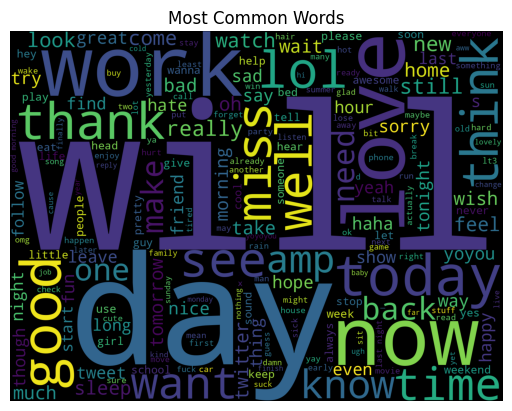

In [57]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
%matplotlib inline

text = ' '.join(df['twitts'])

wc = WordCloud(height=1200, width=1600).generate(text)

plt.imshow(wc)
plt.axis("off")
plt.title("Most Common Words")
plt.show()

## Spelling Correct (using textblob)

##### must install textblob library by using >> *!pip install -U textblob*
##### after install it, call it by using      >> *from textblob import TextBlob*


In [58]:
from textblob import TextBlob

# small test..
x = "thankks forr wattchiing it"
TextBlob(x).correct()

TextBlob("thanks for watching it")

## Tokenization using TextBlob

In [59]:
# small test..
x = "thanks#watching this video. please like it"
TextBlob(x).words

WordList(['thanks', 'watching', 'this', 'video', 'please', 'like', 'it'])

In [60]:
doc = nlp(x)         # nlp was defined previously as "nlp = spacy.load('en_core_web_sm')"
for token in doc:
    print(token)

thanks#watching
this
video
.
please
like
it


from the two previous cells, **tokenization** process must make by using **TextBlob().words**

## Detecting Nouns

In [61]:
# nlp = spacy.load("en_core_web_sm")
x = "Breaking News: Abd-elfattah elsisi, the president of Egypt is looking to sign a deal to mine the moon"
doc = nlp(x)
for noun in doc.noun_chunks:
    print(noun)

Breaking News
Abd-elfattah elsisi
the president
Egypt
a deal
the moon


## Language Translation and Detection

In [62]:
x

'Breaking News: Abd-elfattah elsisi, the president of Egypt is looking to sign a deal to mine the moon'

In [64]:
!pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 8.5 MB/s eta 0:00:0000:0100:01
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=b8e0db686bf614e6780bffe37e6fad7113b296a6ff14863360677e366f38106f
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect


In [66]:
from langdetect import detect       # to detect text language...

detect(x)

'en'

In [67]:
!pip install deep_translator

In [68]:
from deep_translator import GoogleTranslator     # to translate text from auto language (it currently language) into target language...

GoogleTranslator(source="auto", target='fr').translate(x)

'Dernières nouvelles : Abd-elfattah Elsisi, le président égyptien cherche à signer un accord pour exploiter la Lune'

In [69]:
for lang, proto in [("French", "fr"), ("Arabic", "ar"), ("Indian", "hi"), ("German", "de"), ("Chinese", "zh-CN")]:
    print(f"{lang}:\n{GoogleTranslator(source='auto', target=proto).translate(x)} \n")

French:
Dernières nouvelles : Abd-elfattah Elsisi, le président égyptien cherche à signer un accord pour exploiter la Lune 

Arabic:
عاجل: الرئيس المصري عبد الفتاح السيسي يبحث التوقيع على صفقة لتعدين القمر 

Indian:
ब्रेकिंग न्यूज़: मिस्र के राष्ट्रपति अब्द-एलफ़त्ताह एल्सिसी चंद्रमा पर खनन के लिए एक समझौते पर हस्ताक्षर करना चाह रहे हैं 

German:
Eilmeldung: Abd-elfattah elsisi, der Präsident Ägyptens, will einen Vertrag zum Abbau des Mondes unterzeichnen 

Chinese:
突发新闻：埃及总统阿卜杜勒法塔赫·埃尔西西正在寻求签署一项月球开采协议 



## Use TextBlob's Inbuilt Sentiment Classifier

In [70]:
from textblob import TextBlob
from textblob.sentiments import NaiveBayesAnalyzer

x = "We all stands together. We are gonna win this fight"

tb = TextBlob(x, analyzer=NaiveBayesAnalyzer())
tb.sentiment

Sentiment(classification='pos', p_pos=0.9180581552428241, p_neg=0.0819418447571765)

In [71]:
result = tb.sentiment
if result[1]>=0.5:
    print("Positive")
else:
    print("Negative")

Positive
